# Multidimensional Scaling (MDS)

## 1. Definition
MDS represents observations in a low-dimensional space while preserving pairwise dissimilarities. **Metric MDS** tries to preserve numeric dissimilarities; **classical (metric) MDS** uses an eigendecomposition of a double-centered squared-distance matrix.

## 2. Classical MDS derivation
Given Euclidean distance matrix D, square elementwise to obtain $D^{(2)}$, and compute
$$
B=-\frac12 H D^{(2)} H,\qquad H=I-\frac1n\mathbf1\mathbf1^T.
$$
If the distances are Euclidean, B is a centered Gram matrix. Its top positive eigenvectors scaled by square roots of eigenvalues give coordinates. This connects distances to inner products through the polarization identity.

## 3. Why it works and assumptions
For Euclidean distances, classical MDS recovers coordinates up to rotation, reflection and translation when all positive dimensions are retained. With fewer dimensions it gives the best positive-eigenvalue approximation of B, not necessarily the global optimum of the raw stress objective used by iterative metric MDS. Non-Euclidean dissimilarities can yield negative eigenvalues.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import StandardScaler

SEED = 42
X, color = make_swiss_roll(n_samples=180, noise=0.05, random_state=SEED)
X = StandardScaler().fit_transform(X)
D = pairwise_distances(X)


## 4. Classical MDS from scratch

In [2]:
def classical_mds(D, n_components=2):
    D = np.asarray(D, dtype=float)
    if D.ndim != 2 or D.shape[0] != D.shape[1] or not np.allclose(D, D.T, atol=1e-8):
        raise ValueError("D must be a symmetric square distance matrix")
    if not 1 <= n_components < len(D) or np.any(D < 0):
        raise ValueError("Invalid number of dimensions or negative distances")
    n = len(D)
    D2 = D**2
    H = np.eye(n) - np.ones((n,n))/n
    B = -0.5 * H @ D2 @ H
    B = (B + B.T) / 2
    vals, vecs = np.linalg.eigh(B)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    positive = np.maximum(vals[:n_components], 0)
    Y = vecs[:, :n_components] * np.sqrt(positive)[None, :]
    return Y, vals, B

Y_scratch, eigvals, B = classical_mds(D, n_components=2)
print("Top eigenvalues:", np.round(eigvals[:5], 3))
print("Negative eigenvalues:", int(np.sum(eigvals < -1e-8)))


Top eigenvalues: [203.896 186.616 149.488   0.      0.   ]
Negative eigenvalues: 0


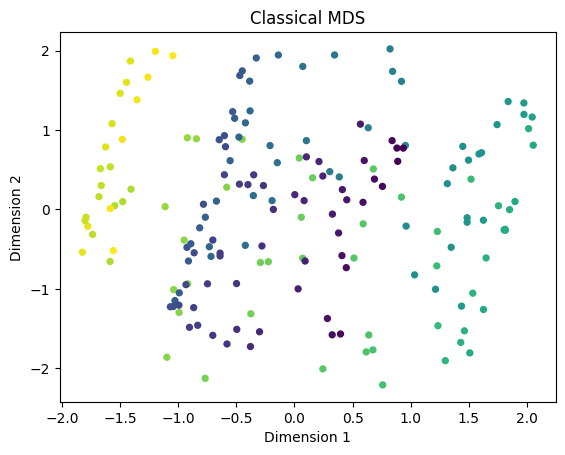

In [3]:
plt.scatter(Y_scratch[:,0], Y_scratch[:,1], c=color, cmap="viridis", s=18)
plt.title("Classical MDS"); plt.xlabel("Dimension 1"); plt.ylabel("Dimension 2"); plt.show()


## 5. Compare with metric MDS

Metric MDS solves an iterative stress minimization problem. Coordinates can be rotated or reflected, so compare pairwise distances and stress-like error.

In [4]:
mds_kwargs = dict(n_components=2, metric=True, dissimilarity="precomputed",
                  random_state=SEED, n_init=1, max_iter=100)
try:
    mds = MDS(normalized_stress="auto", **mds_kwargs)
except TypeError:
    mds = MDS(**mds_kwargs)
Y_metric = mds.fit_transform(D)
D_low = pairwise_distances(Y_scratch)
D_metric = pairwise_distances(Y_metric)
def normalized_distance_error(D_high, D_low):
    return np.linalg.norm(D_high-D_low, "fro") / (np.linalg.norm(D_high, "fro") + 1e-12)
print("Classical MDS relative distance error:", round(normalized_distance_error(D, D_low), 4))
print("Metric MDS relative distance error:", round(normalized_distance_error(D, D_metric), 4))
assert Y_metric.shape == Y_scratch.shape
assert np.isfinite(Y_metric).all()


Classical MDS relative distance error: 0.2678
Metric MDS relative distance error: 0.213


/opt/pyvenv/lib/python3.13/site-packages/sklearn/manifold/_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/manifold/_mds.py:771: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/manifold/_mds.py:779: FutureWarning: Use metric_mds=True instead of metric=True. The support for metric={True/False} will be dropped in 1.10.
  warnings.warn(


## 6. Hyperparameters, complexity and scaling
- `n_components`: output dimensions.
- `dissimilarity`: Euclidean or precomputed dissimilarities.
- Metric MDS uses optimization settings such as `max_iter`, `n_init`, and stopping tolerance.
- A dense distance matrix costs $O(n^2)$ memory and $O(n^2d)$ to compute from d-dimensional observations; eigendecomposition is $O(n^3)$. Iterative metric MDS also repeatedly evaluates pairwise distances.
- MDS is not appropriate for millions of samples in the naive dense form. Sample the data, use landmark MDS, or use methods designed for large-scale neighbor/manifold structure.
- GPU pairwise distance calculations are parallelizable, but dense pair storage and eigensolver costs remain limiting.

## 7. Synthesis and tests

MDS starts from pairwise distances, not necessarily original feature vectors. Classical MDS is an algebraic solution for Euclidean distances; metric MDS is iterative and directly optimizes a stress criterion.

In [5]:
assert Y_scratch.shape == (len(D), 2)
assert np.isfinite(Y_scratch).all()
assert np.allclose(B, B.T, atol=1e-8)
try:
    classical_mds(np.array([1,2,3]), 2)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid D shape to raise")
print("All MDS checks passed.")


All MDS checks passed.
